# **Практическая работа №3. Сравнительный анализ базовых и ансамблевых методов машинного обучения в задачах классификации текстов**

---

## **Введение**

Отзывы об организациях содержат два источника информации: текст с описанием опыта посетителя и оценку от 1 до 5 звёзд. Их сопоставление позволяет выявить случаи, требующие подробного анализа: неоднозначные тексты, расхождения между содержанием и оценкой, а также ошибки моделей.

Методы классификации текстов применяются для определения тональности и прогнозирования оценки по содержанию отзыва. Результаты объединяются со сведениями об организациях и их координатами, чтобы сравнить отзывы выбранных территорий и отобразить выявленные расхождения на карте.

**🎯 Цель работы:** освоить построение и оценку моделей классификации русскоязычных текстов и применить их к анализу отзывов об организациях с учётом пространственного расположения объектов.

**Задачи работы:**

1. Подготовить текстовые данные и сравнить мешок слов, TF-IDF, Word2Vec, Doc2Vec и современные нейросетевые эмбеддинги.
2. Обучить и сравнить классификаторы тональности, подобрать параметры и оценить качество на тестовой выборке.
3. Построить модель прогнозирования оценки по тексту отзыва с разделением данных по организациям.
4. Сформулировать правило отбора отзывов, в которых текст может расходиться с оценкой, и проверить его по результатам чтения.
5. Собрать отзывы выбранных территорий, подготовить сводку по организациям и карты тональности, оценок и расхождений.
6. Сравнить результаты для двух территорий и сформулировать выводы с учётом качества моделей и ограничений выборки.

**Данные:**

- [RuSentiTweet](https://github.com/sismetanin/rusentitweet) — русскоязычные сообщения с разметкой тональности;
- [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) — отзывы об организациях с оценками от 1 до 5;
- свежие отзывы выбранной территории, которые вы соберёте [сборщиком отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews).

**Структура работы:**

| Часть | Вопрос исследования | Результат |
|---|---|---|
| 1. Тональность текста | Какое представление текста и какой классификатор позволяют точнее определить тональность? | Модель тональности и сравнение методов |
| 2. Оценка по тексту | Насколько точно можно предсказать оценку и как отобрать расхождения между текстом и звёздами? | Модель оценки, правило отбора и опорная частота расхождений |
| 3. Анализ территорий | Какие расхождения встречаются в собранных отзывах и различаются ли территории? | Проверенные примеры, сводка по организациям, карты и сравнение двух территорий |

> 📝 **Как выполнять работу.** Выполняйте ячейки сверху вниз. В ячейках `# ВАШ КОД` напишите своё решение; в некоторых из них уже есть заготовка — замените многоточия. Чтобы ответить на вопрос, дважды щёлкните по ячейке «Ответ», впишите текст и нажмите `Shift+Enter`.

---

## **Часть 0. Настройка окружения**

Откройте блокнот в Colab и включите видеокарту: **Среда выполнения → Сменить среду выполнения → GPU**. Затем установите библиотеки и выполните импорты.

In [3]:
# Устанавливаем библиотеки для векторизации, классификации и карт.
%pip install -q scikit-learn==1.7.2 gensim==4.4.0 lightgbm==4.7.0 sentence-transformers==5.2.0 transformers==4.57.6 pyarrow geopandas folium osmnx==2.1.0

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
%pip install torch

  Using cached filelock-4.1.1-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 1.9 MB/s eta 0:01:07
   ---------------------------------------- 0.8/124.1 MB 2.0 MB/s eta 0:01:03
   ---------------------------------------- 0.8/124.1 MB 2.0 MB/s eta 0:01:03
   ---------------------------------------- 0.8/124.1 MB 2.0 MB/s eta 0:01:03
   ---------------------------------------- 1.0/124.1 MB 839.3 kB/s eta 0:02:27
   ---------------------------------------- 1.0/124.1 MB 839.3 kB/s eta 0:02:27
   ---------------------------------------- 1.3/124.1 MB 818.6 kB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os  # Задаём число вычислительных потоков.
from pathlib import Path  # Работаем с путями к файлам.
THREADS = min(6, os.cpu_count() or 1)  # Используем не больше доступного числа процессоров.
os.environ['OMP_NUM_THREADS'] = str(THREADS)  # Ограничиваем потоки вычислительных библиотек.
os.environ['MKL_NUM_THREADS'] = str(THREADS)  # Согласуем потоки линейной алгебры.

import numpy as np  # Работаем с массивами.
import pandas as pd  # Работаем с таблицами.
import matplotlib.pyplot as plt  # Строим графики.
import seaborn as sns  # Показываем распределения и матрицы ошибок.
import torch  # Проверяем доступность видеокарты.
from IPython.display import display  # Выводим таблицы и карты.

SEED = 42  # Фиксируем случайность разделений и обучения.
np.random.seed(SEED)  # Повторяем случайный выбор примеров.
torch.set_num_threads(THREADS)  # Ограничиваем потоки PyTorch.
device = 'cuda' if torch.cuda.is_available() else 'cpu'  # Выбираем устройство для эмбеддингов.
pd.set_option('display.max_colwidth', None)  # Показываем тексты целиком.
plt.rcParams['figure.figsize'] = (9, 4)  # Задаём размер графиков.
print('Устройство:', device)  # Проверяем, подключена ли видеокарта.

Устройство: cpu


> **18+.** Пользовательские тексты могут содержать ненормативную лексику. Для просмотра таблиц с текстами используйте функцию `show(...)`: она заменяет такие слова на `[скрыто]` только при показе, а данные для обучения не меняет.

In [5]:
# Готовая функция для вывода текстов
import base64, gzip, re  # Подключаем средства чтения встроенных правил.
display_pattern = re.compile(gzip.decompress(base64.b64decode('H4sIAAAAAAACCl1QMQ7CMBB7CxvwBBYeknYpEgIxAmK5oVAhNhA/CSKBQmn5gu9HOEknFut8d7F9yYrhdDCcTmDR6p74wQ2NsGy0wgOetBV80elBy0g5rf4aJHu8iWWiqbRpueR67Lq+iD5pFN97OqRSr8Gs6bsuCiU6ynbjrAjIsHrUyuAFr1e9oNZzzoQGNXyOJ5+ZMMlx6+8SWD0QQoZWK8bXU3DpAtQEvQiVuOIjoB1JyGcoTkUXCXeobeO3fIXfRGE4WMG9L7vg9OHYGXa6HG+Zb2crWS+WGymWm9kiHfED+6yyw3MBAAA=')).decode('utf-8'), re.IGNORECASE)  # Подготавливаем фильтр.
def show(frame):  # Маскируем текст только в отображаемой копии.
    shown = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()  # Сохраняем исходные значения.
    for column in shown.select_dtypes(include=['object','string']):  # Обрабатываем текстовые поля.
        shown[column] = shown[column].astype(str).str.replace(display_pattern,'[скрыто]',regex=True)  # Скрываем совпадения.
    display(shown)  # Показываем подготовленную таблицу.

---

## **Часть 1. Тональность текста**

**Задача:** по тексту сообщения определить его тональность — отрицательную, нейтральную или положительную.

**Датасет:** [RuSentiTweet](https://github.com/sismetanin/rusentitweet) содержит русскоязычные сообщения социальной сети, размеченные по тональности. В корпусе есть обучающая и тестовая части. Тестовую часть оставим для итоговой проверки, а из обучающей выделим валидацию для выбора моделей и параметров.

Обученная модель понадобится в частях 2 и 3: она станет первым «читателем» отзывов.

### **1.1. Загрузка и первичный осмотр данных**

> 📚 **Подсказка:** Загрузка корпуса и чтение CSV показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=hJVEXL-bcVRg).

In [6]:
if not Path('rusentitweet').exists():  # При повторном запуске используем уже скачанную папку.
    !git clone -q --depth 1 https://github.com/sismetanin/rusentitweet.git rusentitweet
train_source = pd.read_csv('rusentitweet/rusentitweet_train.csv')  # Читаем обучающую часть.
test_source = pd.read_csv('rusentitweet/rusentitweet_test.csv')  # Читаем тестовую часть.
show(train_source.head())  # Смотрим столбцы и примеры.

,text,label,id
0,Помойму я вкрашилась в Чимина🤧 https://t.co/t2uZTS7NH2,positive,1282311169534038016
1,@namaskaramsaroo Мотоцикль,neutral,1272864221202530309
2,Михаил Мишустин: меры по борьбе с коронавирусом в России были своевременные и правильные https://t.co/bYMCUoZDMk,neutral,1296860899739947008
3,@bbsbro_ доброй ноченьки 💕,speech,1288168112425246721
4,ну что пойду чекну фоточки,neutral,1287678712612364288


**1. Выведите размеры обучающей и тестовой частей, число пропусков и количество примеров каждой исходной метки.**

In [7]:
print("train shape: ", train_source.shape)
print("test shape: ", test_source.shape, "\n")
print("train NaNs sum: ", train_source.isna().sum(), "\n")
print("testNaNs sum: ", test_source.isna().sum(), "\n")
print("train NaNs duplicated: ", train_source.duplicated().sum())
print("testNaNs duplicated: ", test_source.duplicated().sum(), "\n")
print(train_source["label"].value_counts(), "\n")
print(test_source["label"].value_counts(), "\n")

train shape:  (10713, 3)
test shape:  (2679, 3) 

train NaNs sum:  text     0
label    0
id       0
dtype: int64 

testNaNs sum:  text     0
label    0
id       0
dtype: int64 

train NaNs duplicated:  0
testNaNs duplicated:  0 

label
neutral     4273
negative    2638
positive    1931
skip        1474
speech       397
Name: count, dtype: int64 

label
neutral     1068
negative     660
positive     483
skip         369
speech        99
Name: count, dtype: int64 



**2. Покажите по три случайных текста классов `negative`, `neutral` и `positive`.**

In [8]:
for cls in ["negative", "neutral", "positive"]:
    print(f"\nКласс: {cls}")
    print(train_source.loc[train_source["label"] == cls, "text"].sample(3, random_state=SEED))


Класс: negative
6295                                     Максимально допустимая продолжительность видео — 2 минуты 20 секунд.\r\n\r\nО нет.....
4398                                                                                        опять ошибки да ок понятно тупица м
9648    @chern_ov Мне самой кажется эстетичным носы с горбинкой\r\nНо свой из за неё я буквально ненавижу\r\n¯\_༼ •́ ͜ʖ •̀ ༽_/¯
Name: text, dtype: str

Класс: neutral
3630                                                           Правильно пишется "Конституции"
2963    @shkolar92 Так я ж не парней с видео имел ввиду. Ты наверно не совсем понял этот твит)
784                         @ybudyan @SkunkAngry @Alex_zhzhet Квартира в наследство досталась.
Name: text, dtype: str

Класс: positive
5918         хорошо мой павелитель 🙏🏻 https://t.co/pNYA8ucoYw
9143     @JoomOfficialRu вроде смешно https://t.co/Oo3uOblGSb
10349            Ничего необычного) 😂 https://t.co/mYrxsYTtmX
Name: text, dtype: str


**Как читать разметку.** `positive` и `negative` — выраженная положительная или отрицательная оценка; `neutral` — содержательное сообщение без выраженной оценки. `speech` обозначает речевые акты (приветствие, поздравление), `skip` — сообщения, тональность которых определить трудно. В работе используем первые три класса. [Описание корпуса](https://github.com/sismetanin/rusentitweet).

**Вопрос:** Сколько примеров каждого из трёх используемых классов в обучающей части? Почему классы `speech` и `skip` не объединяем с `neutral`?

**Ответ:** neutral-4273, negative-2638, positive-1931. Speech - не содержит эмоции, а skip слишком неоднозначен

---

### **1.2. Очистка и разделение данных**

Один и тот же текст не должен встречаться в нескольких частях: иначе итоговая проверка частично измеряла бы запоминание. Для поиска повторов создаём ключ — текст без различий регистра и пробелов. Повторы с разными метками удаляем как противоречивые. Исходный текст сохраняем для признаков и чтения.

In [9]:
from sklearn.model_selection import train_test_split  # Выделяем валидацию.

def text_key(column):  # Ключ для поиска одинаковых текстов.
    return column.fillna('').astype(str).str.normalize('NFKC').str.replace(r'\s+', ' ', regex=True).str.strip().str.casefold()  # Убираем различия регистра и пробелов.

labels = ['negative', 'neutral', 'positive']  # Три целевых класса.
prepared = {}  # Подготовленные исходные части.
for name, frame in [('train', train_source), ('test', test_source)]:  # Обрабатываем обе части одинаково.
    frame = frame.copy()  # Не меняем исходную таблицу.
    frame['text_key'] = text_key(frame.text)  # Ключ каждого текста.
    conflict = frame.groupby('text_key').label.transform('nunique').gt(1)  # Одинаковые тексты с разными метками.
    keep = frame.label.isin(labels) & frame.text_key.ne('') & ~conflict  # Пригодные записи.
    prepared[name] = frame.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Удаляем повторы.

test = prepared['test']  # Итоговая проверка.
development = prepared['train'].loc[~prepared['train'].text_key.isin(test.text_key)]  # Убираем из обучения тексты теста.
train, valid = train_test_split(development, test_size=0.2, stratify=development.label, random_state=SEED)  # Сохраняем доли классов.
train, valid = train.reset_index(drop=True), valid.reset_index(drop=True)  # Последовательные индексы.

**Выведите численность классов в `train`, `valid` и `test` и проверьте, что ни одна пара частей не имеет общих текстов (по столбцу `text_key`).**

<details>
<summary><b>Пример кода</b></summary>

```python
show(pd.DataFrame({'train': train.label.value_counts(), 'valid': valid.label.value_counts()}))
print('train / valid:', len(set(train.text_key) & set(valid.text_key)))
```

</details>

In [10]:
print(train['label'].value_counts())
print(valid['label'].value_counts())
print(test['label'].value_counts(), "\n") 

print('train / valid:', len(set(train.text_key) & set(valid.text_key)), "\n")
print('train / test:', len(set(train.text_key) & set(test.text_key)), "\n")
print('valid / test:', len(set(valid.text_key) & set(test.text_key)), "\n")

label
neutral     3418
negative    2110
positive    1545
Name: count, dtype: int64
label
neutral     855
negative    528
positive    386
Name: count, dtype: int64
label
neutral     1068
negative     660
positive     483
Name: count, dtype: int64 

train / valid: 0 

train / test: 0 

valid / test: 0 



> 📚 **Подсказка:** train нужен для обучения, valid — для выбора модели и параметров, test — для итоговой оценки после выбора. [**Разделение данных и кросс-валидация**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=hc87mctOPspb).

**Вопрос:** Зачем нужна валидация, если в корпусе уже есть тестовая часть?

**Ответ:** train — учим, validation — выбираем и настраиваем, test — один раз проверяем итог

---

### **1.3. Разведочный анализ и гипотезы**

> 📚 **Подсказка:** [**Занятие 2: распределение классов**](https://colab.research.google.com/drive/1aT36P0Jc-dIjYOx6Hh8yecFSgt-z3Fan#scrollTo=15c684d7); [**Macro-F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=0c5d5827).

**1. Постройте распределение классов в обучающей части.**

<Axes: xlabel='label', ylabel='count'>

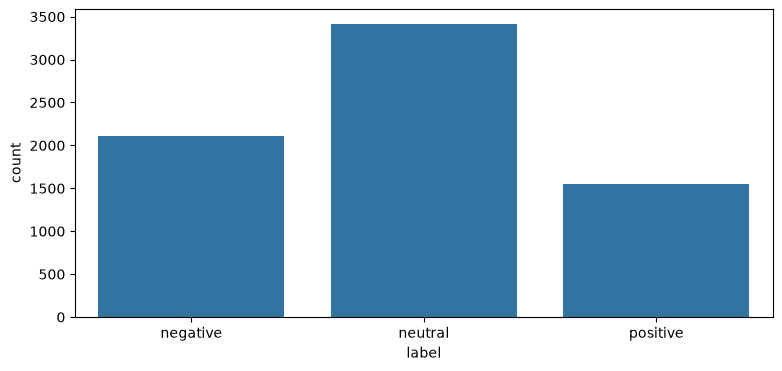

In [11]:
sns.countplot(data=train, x='label', order=labels)

**2. Сравните длину текстов (в символах) по классам с помощью `boxplot`.**

<Axes: xlabel='label', ylabel='text_length'>

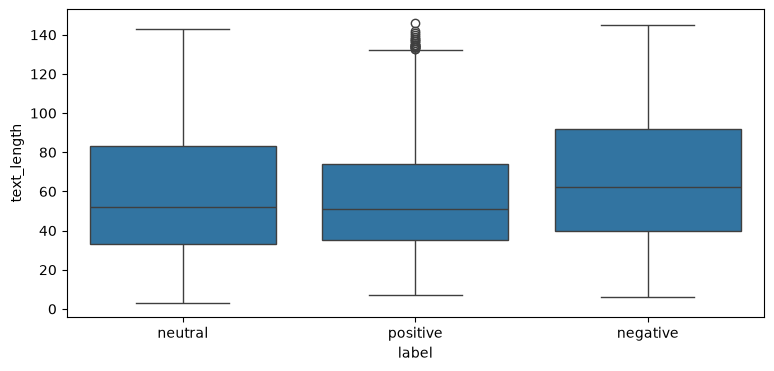

In [12]:
train["text_length"] = train["text"].str.len()
sns.boxplot(data=train, x="label", y="text_length")

Чтобы гипотезы о признаках были осмысленными, сравните способы представления текста, которые будут использованы дальше:

| Представление | Что описывает вектор текста | Обучается на наших данных? |
|---|---|---|
| BoW (мешок слов) | Частоты слов и пар соседних слов | Словарь — да |
| TF-IDF | Те же частоты, взвешенные по редкости слова в обучающих текстах | Словарь и веса — да |
| Средний Word2Vec | Среднее векторов слов текста | Да |
| Doc2Vec | Вектор документа, выведенный обученной моделью | Да |
| E5, Giga | Вектор текста из готовой нейросети, учитывающей контекст слов | Нет, веса готовые |

Главная метрика сравнения — **macro-F1**: среднее F1 по трём классам, где каждый класс имеет одинаковый вес. Дополнительно смотрим accuracy и время обучения.

Сформулируйте **две гипотезы**: одну о представлении текста, другую — о классификаторе или учёте дисбаланса классов. Для каждой укажите наблюдение или теоретическое соображение, ожидаемое изменение macro-F1 и способ проверки.

| № | Наблюдение или соображение | Гипотеза | Как проверить |
|---|---|---|---|
| 1 | ... | ... | ... |
| 2 | ... | ... | ... |

<details>
<summary><b>Подсказка к формулировке гипотез</b></summary>

Мешок слов хранит частоты отдельных слов и, при `ngram_range=(1, 2)`, соседних пар. Пара «не понравилось» может войти в словарь, но порядок всего предложения и близость синонимов такое представление не описывает. Какое представление может учесть больше контекста и для какого классификатора это окажется полезным? Посмотрите на распределение классов: как самый частый класс повлияет на accuracy постоянного прогноза?

Пример гипотезы: «На эмбеддингах E5 SVM получит macro-F1 выше, чем на TF-IDF, потому что вектор E5 учитывает контекст; проверим по таблице сравнения».

</details>

**Гипотезы:** _______________

| № | Наблюдение или соображение                                                                                                               | Гипотеза                                                                                                    | Как проверить                                                                |
| - | ---------------------------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------- |
| 1 | BoW и TF-IDF учитывают частоты слов и пар слов, но не весь контекст и близость синонимов; E5 строит вектор всего текста с учётом смысла. | SVM на эмбеддингах E5 получит более высокий macro-F1, чем SVM на TF-IDF.                                    | Сравнить macro-F1 SVM на E5 и TF-IDF в таблице результатов.                  |
| 2 | Класс neutral встречается чаще других, поэтому модель, всегда предсказывающая neutral, может получить заметную accuracy.                 | Постоянный прогноз «neutral» даст высокую accuracy, но низкий macro-F1 из-за ошибок на negative и positive. | Посчитать accuracy и macro-F1 для DummyClassifier(strategy="most_frequent"). |

**Вопрос:** Почему при таком распределении классов нельзя выбирать модель только по accuracy?

**Ответ:** Потому что при несбалансированных классах accuracy в основном отражает самый частый класс и может скрывать плохую работу модели на редких классах.

---

### **1.4. Мешок слов и TF-IDF**

> 📚 **Подсказка:** Построение мешка слов и TF-IDF показано в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=9jTeKixplgYk). Сравните методы `fit_transform` и `transform`.

Мешок слов превращает текст в частоты слов и соседних пар: каждому элементу словаря соответствует столбец матрицы. TF-IDF изменит веса этих частот, чтобы отличать распространённые слова от более редких.

Словарь и веса строим **только по обучающей части**. Валидацию и тест преобразуем теми же объектами методом `transform`: иначе одинаковые столбцы могут обозначать разные слова.

**1. Создайте `bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)` и получите `X_bow_train`, `X_bow_valid`, `X_bow_test`.**

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer  # Словарные признаки.


bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, dtype=np.float64)


X_bow_train = bow.fit_transform(train["text"])
X_bow_valid = bow.transform(valid["text"])
X_bow_test = bow.transform(test["text"])
# fit_transform вызывается только на train: векторизатор изучает словарь по обучающей выборке. Для valid и test применяется тот же transform, чтобы избежать утечки данных.

print(bow.get_feature_names_out())
print(X_bow_train.toarray())

['00' '000' '01' ... 'яяяяя' 'ёб' 'ёжик']
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


**2. Создайте `tfidf = TfidfTransformer()` и получите `X_tfidf_train`, `X_tfidf_valid`, `X_tfidf_test` из матриц мешка слов.**

In [14]:
tfidf = TfidfTransformer()

X_tfidf_train = tfidf.fit_transform(X_bow_train)
X_tfidf_valid = tfidf.transform(X_bow_valid)
X_tfidf_test = tfidf.transform(X_bow_test)

**Вопрос:** Что изменится, если вызвать `fit_transform` отдельно для тестовой части? Почему такая оценка будет некорректной?

**Ответ:** Оценка не будет независимой, потому что мы будем извлекать признаки на тестовой выборке

---

### **1.5. Word2Vec**

Word2Vec обучается представлять каждое слово вектором так, чтобы слова из похожих контекстов получали близкие векторы. Для текста возьмём среднее векторов его слов. Частицу «не» при токенизации сохраняем.

In [15]:
import re  # Выделяем слова регулярным выражением.
def tokenize(text):  # Одинаковая токенизация для всех частей.
    return re.findall(r'[а-яёa-z]+', text.lower())  # Русские и латинские слова в нижнем регистре.
tokens_train = [tokenize(text) for text in train.text]  # Слова обучающих текстов.
print(tokenize('Мне НЕ понравилось обслуживание!'))  # Проверяем сохранение «не».

['мне', 'не', 'понравилось', 'обслуживание']


> 📚 **Подсказка:** [**Word2Vec в Gensim**](https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec). Модель обучается только на `tokens_train`.

**1. Обучите `word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, workers=1, seed=SEED)`.**

In [23]:
from gensim.models import Word2Vec  # Обучение векторов слов.
word_model = Word2Vec(tokens_train, vector_size=100, window=5, min_count=2, sg=1, epochs=20, workers=1, seed=SEED)

In [24]:
def word_vectors(texts):  # Средний вектор известных слов каждого текста.
    tokens = [tokenize(text) for text in texts]  # Токенизируем тексты.
    return np.vstack([word_model.wv.get_mean_vector(words, pre_normalize=False) if words else np.zeros(100) for words in tokens])  # Для текста без слов — нулевой вектор.

**2. Получите `X_word_train`, `X_word_valid`, `X_word_test` функцией `word_vectors`.**

In [26]:
X_word_train = word_vectors(train["text"])
X_word_valid = word_vectors(valid["text"])
X_word_test = word_vectors(test["text"])

print(X_word_train.shape, X_word_valid.shape, X_word_test.shape)

(7073, 100) (1769, 100) (2211, 100)


**Вопрос:** Почему средний Word2Vec не различает тексты «не хорошо, а плохо» и «не плохо, а хорошо»?

**Ответ:** Потому что средний Word2Vec усредняет векторы слов без учёта их порядка и роли отрицания.

---

### **1.6. Doc2Vec**

> 📚 **Подсказка:** `TaggedDocument`, обучение и `infer_vector` показаны в [**Теории №7**](https://colab.research.google.com/github/Alexandre77777/data_mining/blob/main/5.%20%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F%20%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%9D%D0%B0%D0%B8%D0%B2%D0%BD%D0%BE%D0%B3%D0%BE%20%D0%91%D0%B0%D0%B9%D0%B5%D1%81%D0%B0.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%20%D0%BE%D0%BF%D0%BE%D1%80%D0%BD%D1%8B%D1%85%20%D0%B2%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%BE%D0%B2/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F/%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%E2%84%967_%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BC%D0%B5%D1%82%D0%BE%D0%B4%D0%BE%D0%B2_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%BE%D0%B3%D0%BE_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F_%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D0%B8_%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%BE%D0%B2.ipynb#scrollTo=bZwW8qZ4lvJ7).

Doc2Vec обучает представление целого документа. `TaggedDocument` связывает список слов с меткой документа; здесь метка — номер обучающего текста, а не его класс тональности. После обучения `infer_vector` получает вектор переданного текста. В готовой функции `doc_vectors` этот способ одинаков для обучения, валидации и теста.

**1. Создайте `documents` — список `TaggedDocument(words, [i])` для обучающих текстов — и обучите `doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2, dm=1, epochs=30, workers=1, seed=SEED)`.**

In [32]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument  # Векторы документов.

documents = [TaggedDocument(words=doc.split(), tags=[i]) for i, doc in enumerate(train["text"])]
doc_model = Doc2Vec(documents, vector_size=100, window=5, min_count=2, dm=1, epochs=30, workers=1, seed=SEED)

In [20]:
def doc_vectors(texts):  # Одинаково получаем векторы знакомых и новых текстов.
    vectors = []  # Один вектор на текст.
    for text in texts:  # Сохраняем порядок текстов.
        words = tokenize(text)  # Та же токенизация.
        doc_model.random.seed(SEED)  # Повторяемый вывод вектора.
        vectors.append(doc_model.infer_vector(words, epochs=30) if words else np.zeros(100))  # Для текста без слов — нулевой вектор.
    return np.vstack(vectors)  # Матрица: строка на текст.

**2. Получите `X_doc_train`, `X_doc_valid`, `X_doc_test` функцией `doc_vectors`.**

In [33]:
X_doc_train = doc_vectors(train["text"])
X_doc_valid = doc_vectors(valid["text"])
X_doc_test = doc_vectors(test["text"])

---

### **1.7. Нейросетевые эмбеддинги: E5 и Giga**

Энкодер — готовая нейросеть, которая превращает текст в вектор с учётом контекста слов. Библиотека `sentence-transformers` загружает модель, а метод `encode` токенизирует тексты, обрабатывает их пакетами и возвращает векторы. Веса энкодеров мы **не дообучаем**: они остаются такими, как их опубликовали авторы.

Используем две модели: компактную многоязычную [multilingual-e5-small](https://huggingface.co/intfloat/multilingual-e5-small) и [Giga-Embeddings-instruct-480M](https://huggingface.co/ai-sage/Giga-Embeddings-instruct-480M-0826), обученную в том числе на русских текстах. Параметр `revision` закрепляет версию файлов модели, чтобы результат воспроизводился.

In [34]:
from sentence_transformers import SentenceTransformer  # Интерфейс энкодеров.
texts = train.text.tolist() + valid.text.tolist() + test.text.tolist()  # Тексты трёх частей в известном порядке.
split_positions = [len(train), len(train) + len(valid)]  # Границы частей в общей матрице.

e5 = SentenceTransformer('intfloat/multilingual-e5-small', revision='614241f622f53c4eeff9890bdc4f31cfecc418b3', device=device, model_kwargs={'dtype': torch.float32})  # Загружаем E5.
X_e5 = e5.encode(texts, prompt='query: ', batch_size=32, normalize_embeddings=True, show_progress_bar=True)  # E5 обучалась с префиксом query:.
X_e5_train, X_e5_valid, X_e5_test = np.split(X_e5, split_positions)  # Возвращаем три части.
print('Размерность E5:', X_e5.shape)  # Строк столько же, сколько текстов.

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Batches:  12%|█▏        | 43/346 [00:38<04:27,  1.13it/s]


KeyboardInterrupt: 

**Загрузите Giga и получите её векторы по аналогии с ячейкой E5.**

1. Создайте `giga` вызовом `SentenceTransformer` с идентификатором `'ai-sage/Giga-Embeddings-instruct-480M-0826'` и `revision='1763d603adac8057bd6482a708001b0ed2e0a903'`. Модель использует собственный код архитектуры, поэтому добавьте `trust_remote_code=True`. Параметры `device` и `model_kwargs` возьмите из примера E5.
2. Получите `X_giga` методом `encode` для того же списка `texts`. Префикс не нужен; задайте `batch_size=16` и `normalize_embeddings=True`.
3. Разделите матрицу на `X_giga_train`, `X_giga_valid`, `X_giga_test` по `split_positions` и выведите её размерность.

In [ ]:
# ВАШ КОД

> 📚 **Подсказка:** [**Метод encode**](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html#sentence_transformers.SentenceTransformer.encode) вычисляет признаки при уже обученных весах.

**Вопрос:** Почему `encode` можно применить сразу ко всем трём частям, а Word2Vec нельзя обучать на всех текстах сразу?

**Ответ:** _______________

---

### **1.8. Сравнение классификаторов**

> 📚 **Подсказка:** [**Занятие 4: KNN, SVM, деревья**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=fa20d7f9); [**логистическая регрессия**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=00b7d3cc); [**варианты наивного Байеса**](https://scikit-learn.org/stable/modules/naive_bayes.html); [**LGBMClassifier**](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).

Сравним шесть классификаторов на всех шести представлениях. Дополнительно проверим варианты наивного Байеса: Multinomial, Complement и Bernoulli — на словарных признаках, Gaussian — на плотных векторах. Multinomial и Complement требуют неотрицательных признаков, поэтому к эмбеддингам их не применяем.

In [ ]:
from sklearn.base import clone  # Независимые копии моделей.
from sklearn.pipeline import make_pipeline  # Масштабирование вместе с моделью.
from sklearn.preprocessing import StandardScaler, Normalizer, normalize  # Масштабирование и нормировка.
from scipy import sparse  # Отличаем разреженные матрицы.
from time import perf_counter  # Измеряем время.
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay  # Метрики.
from sklearn.neighbors import KNeighborsClassifier  # Ближайшие соседи.
from sklearn.svm import SVC  # SVM с ядром.
from sklearn.linear_model import LogisticRegression  # Логистическая регрессия.
from sklearn.tree import DecisionTreeClassifier  # Дерево решений.
from sklearn.ensemble import RandomForestClassifier  # Случайный лес.
from lightgbm import LGBMClassifier  # Градиентный бустинг.
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB, GaussianNB  # Наивный Байес.

features = {  # Название представления → матрицы train, valid, test.
    'BoW': (X_bow_train, X_bow_valid, X_bow_test),
    'TF-IDF': (X_tfidf_train, X_tfidf_valid, X_tfidf_test),
    'Word2Vec': (X_word_train, X_word_valid, X_word_test),
    'Doc2Vec': (X_doc_train, X_doc_valid, X_doc_test),
    'E5': (X_e5_train, X_e5_valid, X_e5_test),
    'Giga': (X_giga_train, X_giga_valid, X_giga_test),
}

**1. Создайте словарь `base_models` с шестью классификаторами и начальными параметрами из таблицы.** Параметры можно изменить позднее, при проверке гипотез.

| Ключ | Классификатор и начальные параметры |
|---|---|
| `'KNN'` | `KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS)` |
| `'SVM RBF'` | `SVC(C=3, kernel='rbf', class_weight='balanced', cache_size=512)` |
| `'LogReg'` | `LogisticRegression(C=1, max_iter=2000, class_weight='balanced')` |
| `'Decision Tree'` | `DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=SEED)` |
| `'Random Forest'` | `RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=THREADS, random_state=SEED)` |
| `'LightGBM'` | `LGBMClassifier(n_estimators=150, num_leaves=31, learning_rate=0.05, class_weight='balanced', n_jobs=THREADS, verbosity=-1)` |

In [ ]:
base_models = {
    'KNN': KNeighborsClassifier(n_neighbors=11, weights='distance', algorithm='brute', n_jobs=THREADS),
    # ВАШ КОД: добавьте остальные пять классификаторов из таблицы
}

**2. Создайте словари `lexical_nb` с ключами `'Multinomial NB'`, `'Complement NB'`, `'Bernoulli NB'` (везде `alpha=1`, для Bernoulli также `binarize=0`) и `dense_nb` с ключом `'Gaussian NB'` (`var_smoothing=1e-8`).**

In [ ]:
# ВАШ КОД

Для одной связки достаточно трёх привычных шагов: `model.fit(X_bow_train, train.label)`, `model.predict(X_bow_valid)` и расчёт метрики. Готовый цикл ниже повторяет их для всех совместимых сочетаний.

KNN, SVM, логистическая регрессия и Gaussian NB чувствительны к масштабу признаков. Для разреженных BoW и TF-IDF `Normalizer` приводит длину вектора каждого текста к единице, для плотных векторов `StandardScaler` масштабирует координаты по обучающей части. `Pipeline` хранит преобразование вместе с моделью и применяет его к новым данным. [Масштабирование](https://scikit-learn.org/stable/modules/preprocessing.html), [Pipeline](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=31b5c1e9).

In [ ]:
scaled_models = ['KNN', 'SVM RBF', 'LogReg', 'Gaussian NB']  # Модели, которым нужно масштабирование.
rows, fitted = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in features.items():  # Перебираем представления.
    models = {**base_models, **(lexical_nb if sparse.issparse(X_train) else dense_nb)}  # Добавляем совместимые варианты Байеса.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая необученная копия.
        if name in scaled_models:  # Масштабируем признаки внутри Pipeline.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Преобразование учится только на train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, train.label)  # Обучаем на train.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(valid.label, prediction, average='macro'), 'accuracy': accuracy_score(valid.label, prediction), 'fit_seconds': fit_seconds})  # Сохраняем метрики.
        fitted[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rows[-1]['macro_f1'], 3))  # Следим за ходом сравнения.

Теперь у каждой связки есть оценка на одной и той же валидационной выборке. Таблица позволит выбрать кандидатов для настройки, а время обучения — оценить стоимость такого выбора.

**3. Создайте таблицу `comparison` из списка `rows`, отсортируйте её по `macro_f1` и выведите.**

In [ ]:
# ВАШ КОД

**4. Постройте тепловую карту macro-F1: строки — классификаторы, столбцы — представления.**

<details>
<summary><b>Пример кода</b></summary>

```python
sns.heatmap(comparison.pivot(index='model', columns='representation', values='macro_f1'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Macro-F1 на валидации')
plt.show()
```

</details>

In [ ]:
# ВАШ КОД

Сравним модели с правилом, которое не читает текст: всегда выдавать самый частый класс обучения. Это базовый уровень, который помогает понять, что дали признаки и обучение.

**5. Оцените постоянный прогноз самого частого класса: найдите этот класс по train и рассчитайте accuracy и macro-F1 на valid.**

> 📚 **Подсказка:** [**DummyClassifier**](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) со стратегией `most_frequent`.

In [ ]:
# ВАШ КОД

**Вопрос:** Улучшили ли эмбеддинги E5 и Giga результат каждого классификатора по сравнению с TF-IDF? Приведите два-три примера из тепловой карты. Как выглядят результаты Word2Vec и Doc2Vec относительно TF-IDF? Насколько лучшие модели превосходят постоянный прогноз?

**Ответ:** _______________

---

### **1.9. Кросс-валидация и подбор параметров**

> 📚 **Подсказка:** [**Кросс-валидация и подбор гиперпараметров**](https://colab.research.google.com/drive/1xSmltveF3hdM-Hf6tDO88ME7zqQAu0MT#scrollTo=5UlBaXOpxQkL); [**параметры модели в Pipeline**](https://colab.research.google.com/drive/1S_j8HeJEeUU83cjc7cA3Rpkiya-BNiE1#scrollTo=f147b7da).

Оценка на одной валидационной выборке зависит от того, какие тексты в неё попали. Кросс-валидация покажет, насколько меняется результат при нескольких разделениях обучающей части.

**1. Оцените устойчивость одной словарной связки.** Соберите `make_pipeline(CountVectorizer(...), TfidfTransformer(), ComplementNB())` с параметрами словаря из раздела 1.4 и оцените её на `train.text` тремя стратифицированными разбиениями: `StratifiedKFold(3, shuffle=True, random_state=SEED)`, `scoring='f1_macro'`. Векторизатор находится внутри Pipeline, поэтому словарь каждого разбиения строится только по его обучающим текстам. Выведите три оценки, их среднее и стандартное отклонение.

In [ ]:
# ВАШ КОД

**2. Подберите параметр для двух перспективных связок.** По таблице `comparison` выберите две связки и обоснуйте выбор. Для каждой проверьте три значения одного параметра. Запишите выбор в список `choices` в формате `(представление, модель, параметр, [значение1, значение2, значение3])`; первые два элемента должны совпадать с названиями в `comparison`.

Для моделей внутри Pipeline имя параметра содержит название шага: `svc__C` для SVM, `logisticregression__C` для логистической регрессии, `kneighborsclassifier__n_neighbors` для KNN. Для остальных — просто имя: `num_leaves` (LightGBM), `max_depth` (дерево), `alpha` (Байес). Доступные имена выводит `fitted[(представление, модель)].get_params()`.

<details>
<summary><b>Пример кода</b></summary>

```python
choices = [
    ('TF-IDF', 'Complement NB', 'alpha', [0.1, 1, 3]),
    ('E5', 'SVM RBF', 'svc__C', [1, 3, 10]),
]
```

</details>

In [ ]:
choices = [
    # ВАШ КОД
]

In [ ]:
tuning, candidates = [], {}  # Результаты подбора и обученные варианты.
for representation, name, parameter, values in choices:  # Перебираем выбранные связки.
    X_train, X_valid, _ = features[representation]  # Используем уже рассчитанные признаки.
    base = fitted[(representation, name)]  # Исходная обученная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, train.label)  # Повторно не обучаем исходный вариант.
        score = f1_score(valid.label, model.predict(X_valid), average='macro')  # Оцениваем на валидации.
        tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': score})  # Сохраняем результат.
        candidates[(representation, name, value)] = model  # Сохраняем вариант модели.
tuning_table = pd.DataFrame(tuning).sort_values('macro_f1', ascending=False)  # Лучший вариант первым.
show(tuning_table.round(3))  # Выводим результаты подбора.

**3. Сохраните лучший вариант:** `sentiment_model` — модель из `candidates` для первой строки `tuning_table`, `sentiment_representation` — её представление.

In [ ]:
# ВАШ КОД

**Вопрос:** Какие гипотезы поддерживаются полученными результатами, а какие нет? Приведите значения macro-F1 для сравниваемых вариантов. Что изменил подбор параметра и насколько различаются три оценки кросс-валидации?

**Ответ:** _______________

---

### **1.10. Итоговая проверка на тесте**

> 📚 **Подсказка:** [**Матрица ошибок**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=4c672369); [**Precision, Recall и F1**](https://colab.research.google.com/drive/1P5GxyckR2Bb5clpEs2EflKo1JU7D5ULu#scrollTo=7122ac70).

Модель и параметры выбраны по валидации. Теперь проверим их на текстах, которые не участвовали в выборе. Отчёт покажет качество каждого класса, матрица ошибок — какие классы путаются, а чтение примеров поможет понять характер ошибок. После этой проверки параметры модели больше не меняем.

**1. Получите `sentiment_prediction` для тестовой матрицы `features[sentiment_representation][2]` и выведите `classification_report`.**

In [ ]:
# ВАШ КОД

**2. Постройте матрицу ошибок.**

In [ ]:
# ВАШ КОД: ConfusionMatrixDisplay.from_predictions(...)

**3. Выведите десять случайных ошибочных прогнозов: текст, разметку и прогноз.**

In [ ]:
# ВАШ КОД

**Вопрос:** Выберите две показанные ошибки. Для каждой укажите разметку, прогноз и слова, которые могли запутать модель. Есть ли в этих текстах сарказм, отрицание или недостаток контекста?

**Ответ:** _______________

---

### **1.11. Выводы по части 1**

Опишите, какое представление текста и какой классификатор вы выбрали и почему. Приведите macro-F1 на валидации и тесте и укажите, какие классы модель путает чаще всего.

**Вывод:** _______________

---

## **Часть 2. Звёзды по тексту отзыва**

**Задача:** по тексту отзыва предсказать оценку автора от 1 до 5. Каждая оценка — отдельный класс.

**Датасет:** [Geo Reviews Dataset 2023](https://github.com/yandex/geo-reviews-dataset-2023) содержит 500 000 отзывов об организациях с текстом, названием, адресом, рубриками и оценкой. Описание и лицензия — в официальном репозитории; загрузим [опубликованную копию](https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023) в формате Parquet.

Здесь звёзды известны и служат целевой переменной для обучения. При применении будем сравнивать прогноз по тексту с оценкой автора и отбирать заметные расхождения для чтения. Обученная модель станет вторым «читателем», дополняющим модель тональности.

### **2.1. Загрузка и очистка**

In [ ]:
dataset_url = 'https://huggingface.co/datasets/d0rj/geo-reviews-dataset-2023/resolve/02366bc66bd43aa69e707747487ec8f3c22cac84/data/train-00000-of-00001-49261e4e5a35a5a0.parquet'  # Закреплённая версия набора.
local_parquet = Path('geo_reviews.parquet')  # Локальная копия для повторных запусков.
if not local_parquet.exists():  # Скачиваем один раз.
    pd.read_parquet(dataset_url).to_parquet(local_parquet)  # Сохраняем таблицу на диск среды.
rating_source = pd.read_parquet(local_parquet)  # Читаем отзывы.
show(rating_source.head(3))  # Смотрим столбцы.

**Выведите число отзывов, распределение оценок и число пропусков в каждом столбце.**

In [ ]:
# ВАШ КОД

Готовая ячейка ниже оставляет оценки 1–5, удаляет пустые и повторные тексты и формирует ключ организации из нормированных названия и адреса. Название и адрес не входят в признаки модели: они нужны, чтобы отзывы одной организации не попали одновременно в обучение и тест.

In [ ]:
rating_df = rating_source.copy()  # Рабочая копия.
rating_df['text_key'] = text_key(rating_df.text)  # Ключ текста из части 1.
conflict = rating_df.groupby('text_key').rating.transform('nunique').gt(1)  # Одинаковые тексты с разными оценками.
keep = rating_df.rating.isin([1, 2, 3, 4, 5]) & rating_df.name_ru.notna() & rating_df.address.notna() & rating_df.text_key.ne('') & ~conflict  # Пригодные записи.
rating_df = rating_df.loc[keep].drop_duplicates('text_key').reset_index(drop=True)  # Один экземпляр каждого текста.
rating_df['organization_key'] = text_key(rating_df.name_ru) + ' | ' + text_key(rating_df.address)  # Приближённый ключ организации.
print('Пригодных отзывов:', len(rating_df))  # Объём после очистки.

**Вопрос:** Какая доля отзывов имеет пять звёзд? Почему записи с оценкой 0 исключаем из этой задачи?

**Ответ:** _______________

---

### **2.2. Выборка и разделение по организациям**

Для сравнения моделей возьмём 10 000 отзывов, сохранив доли оценок. Все представления и классификаторы используют одни и те же строки.

**1. Получите `rating_sample` вызовом `train_test_split(rating_df, train_size=10000, stratify=rating_df.rating, random_state=SEED)` (вторую часть результата не используем) и сравните доли оценок в `rating_df` и `rating_sample`.**

In [ ]:
# ВАШ КОД

> 📚 **Подсказка:** [**GroupShuffleSplit**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) помещает все строки одной группы в одну часть.

Отзывы одной организации похожи: в них повторяются названия блюд, имена сотрудников, одни и те же проблемы. Если такие отзывы попадут и в обучение, и в тест, модель получит подсказку, которой не будет у новой организации. Поэтому делим не отзывы, а организации: 20% — тест, четверть оставшихся — валидация.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit  # Разделение целыми группами.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)  # Отделяем тест.
remaining, test_indices = next(splitter.split(rating_sample, groups=rating_sample.organization_key))  # Индексы строк.
development_ratings = rating_sample.iloc[remaining]  # Обучение и валидация.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED + 1)  # Отделяем валидацию.
train_indices, valid_indices = next(splitter.split(development_ratings, groups=development_ratings.organization_key))  # Индексы строк.
rating_train = development_ratings.iloc[train_indices].reset_index(drop=True)  # Обучение.
rating_valid = development_ratings.iloc[valid_indices].reset_index(drop=True)  # Валидация.
rating_test = rating_sample.iloc[test_indices].reset_index(drop=True)  # Тест.
print('Размеры:', len(rating_train), len(rating_valid), len(rating_test))  # Доли задавались для организаций, а не отзывов.

**2. Проверьте, что ни одна пара частей не имеет общих организаций (`organization_key`) и общих текстов (`text_key`).**

In [ ]:
# ВАШ КОД

---

### **2.3. Признаки отзывов**

Сравним словарные признаки с лучшим энкодером части 1. Энкодер используем повторно, а классификаторы обучаем заново: у них новая целевая переменная.

**1. Создайте `rating_bow = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, dtype=np.float64)` и `rating_tfidf = TfidfTransformer()`. Получите матрицы `R_bow_train`, `R_bow_valid`, `R_bow_test` и `R_tfidf_train`, `R_tfidf_valid`, `R_tfidf_test`, обучая словарь и веса только на `rating_train`.**

In [ ]:
# ВАШ КОД

Повторно используем один из готовых энкодеров: его веса не зависят от целевой переменной. Выбор по части 1 — отправная точка; преимущество на отзывах проверим отдельным сравнением со словарными признаками.

**2. По таблице `comparison` выберите среди `'E5'` и `'Giga'` представление с наибольшим macro-F1 и сохраните его название в `modern_best`.**

In [ ]:
# ВАШ КОД

**Длинные отзывы.** Энкодер принимает ограниченное число токенов — частей слов и знаков. Отзывы бывают длиннее этого предела, а скрытое обрезание потеряло бы конец текста, где автор часто подводит итог. Готовая функция `review_vectors` делит длинный отзыв на фрагменты, получает их векторы и объединяет с весами по длине; короткий отзыв проходит одним фрагментом. Функция `text_features` получает признаки новых текстов тем же способом, что при обучении модели, — она понадобится в части 3. [Ограничение длины входа](https://www.sbert.net/examples/sentence_transformer/applications/computing-embeddings/README.html#input-sequence-length).

In [ ]:
# Готовые функции признаков для новых текстов
def review_vectors(texts, encoder, prompt=''):  # Векторы отзывов любой длины.
    tokenized = encoder.tokenizer(list(texts), add_special_tokens=False)['input_ids']  # Токены каждого текста.
    pieces, owners, weights = [], [], []  # Фрагменты, номер исходного отзыва и вес.
    capacity = encoder.max_seq_length - 32  # Место для префикса и служебных токенов.
    for i, ids in enumerate(tokenized):  # Перебираем отзывы.
        for start in range(0, max(1, len(ids)), capacity):  # Делим на фрагменты, сохраняя конец текста.
            chunk = ids[start:start + capacity]  # Очередной фрагмент.
            pieces.append(encoder.tokenizer.decode(chunk))  # Текст фрагмента.
            owners.append(i)  # Номер исходного отзыва.
            weights.append(max(1, len(chunk)))  # Вес по длине.
    vectors = encoder.encode(pieces, prompt=prompt, batch_size=16, normalize_embeddings=True, show_progress_bar=True)  # Векторы фрагментов.
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float32)  # Строка на отзыв.
    np.add.at(matrix, owners, vectors * np.asarray(weights, dtype=np.float32)[:, None])  # Складываем фрагменты с весами.
    return normalize(matrix)  # Единичная длина, как у encode.

_feature_cache = {}  # Признаки уже обработанных наборов текстов.
def text_features(texts, representation, part):  # Признаки текстов для модели части 1 или части 2.
    texts = [str(text) for text in texts]  # Список строк.
    encoders = {'E5': (e5, 'query: '), 'Giga': (giga, '')}  # Энкодеры и их префиксы.
    key = (representation if representation in encoders else (representation, part), hash(tuple(texts)))  # Энкодер одинаков в обеих частях.
    if key not in _feature_cache:  # Считаем признаки один раз.
        if representation in encoders:  # Нейросетевой энкодер.
            _feature_cache[key] = review_vectors(texts, *encoders[representation])  # Длинные тексты по фрагментам.
        elif representation in ('BoW', 'TF-IDF'):  # Словарные признаки.
            counts = (bow if part == 1 else rating_bow).transform(texts)  # Словарь нужной части.
            _feature_cache[key] = counts if representation == 'BoW' else (tfidf if part == 1 else rating_tfidf).transform(counts)  # Веса нужной части.
        else:  # Word2Vec и Doc2Vec обучены в части 1.
            _feature_cache[key] = word_vectors(texts) if representation == 'Word2Vec' else doc_vectors(texts)  # Те же функции.
    return _feature_cache[key]  # Матрица признаков.

**3. Получите векторы всех 10 000 отзывов одним вызовом `text_features(rating_texts, modern_best, part=2)`, где `rating_texts` — тексты train, valid и test подряд. Разделите матрицу на `R_modern_train`, `R_modern_valid`, `R_modern_test` и измерьте время расчёта.**

In [ ]:
# ВАШ КОД

---

### **2.4. Сравнение классификаторов**

В части 1 мы выбрали алгоритмы для тональности. Теперь обучим выбранные алгоритмы предсказывать пять классов звёзд. `clone` создаёт необученную копию с теми же настройками; обученный классификатор тональности сохраняем для его собственной задачи.

**1. Создайте словарь `rating_estimators` из трёх классификаторов:**

- `'SVM RBF'`: `SVC(C=1, kernel='rbf', class_weight='balanced', cache_size=512)`;
- `'LogReg'`: копия `clone(base_models['LogReg'])`;
- ещё один классификатор из `base_models` (KNN, Decision Tree, Random Forest или LightGBM), который вы выбираете по качеству и времени обучения в части 1. Ключ должен совпадать с названием в `base_models`.

In [ ]:
rating_estimators = {
    # ВАШ КОД
}

Готовый цикл обучает каждую связку на `rating_train` и оценивает на `rating_valid`. Для словарных признаков добавлены Multinomial и Complement NB. **MAE** — средняя абсолютная ошибка в звёздах: прогноз 2 при оценке 5 даёт ошибку 3.

In [ ]:
from sklearn.metrics import mean_absolute_error  # Ошибка в звёздах.
rating_features = {'BoW': (R_bow_train, R_bow_valid, R_bow_test), 'TF-IDF': (R_tfidf_train, R_tfidf_valid, R_tfidf_test), modern_best: (R_modern_train, R_modern_valid, R_modern_test)}  # Готовые признаки.
rating_rows, rating_models = [], {}  # Метрики и обученные модели.
for representation, (X_train, X_valid, _) in rating_features.items():  # Перебираем представления.
    models = {**rating_estimators, **({'Multinomial NB': MultinomialNB(), 'Complement NB': ComplementNB()} if sparse.issparse(X_train) else {})}  # Байес только для частот.
    for name, estimator in models.items():  # Перебираем классификаторы.
        model = clone(estimator)  # Новая копия.
        if name in scaled_models:  # Масштабирование, как в части 1.
            model = make_pipeline(Normalizer() if sparse.issparse(X_train) else StandardScaler(), model)  # Учим преобразование по train.
        start = perf_counter()  # Начало обучения.
        model.fit(X_train, rating_train.rating)  # Обучаем на звёздах.
        fit_seconds = perf_counter() - start  # Длительность обучения.
        prediction = model.predict(X_valid)  # Прогноз валидации.
        rating_rows.append({'representation': representation, 'model': name, 'macro_f1': f1_score(rating_valid.rating, prediction, average='macro'), 'accuracy': accuracy_score(rating_valid.rating, prediction), 'mae_stars': mean_absolute_error(rating_valid.rating, prediction), 'fit_seconds': fit_seconds})  # Метрики.
        rating_models[(representation, name)] = model  # Сохраняем модель.
        print(representation, name, round(rating_rows[-1]['macro_f1'], 3))  # Ход сравнения.
rating_comparison = pd.DataFrame(rating_rows).sort_values('macro_f1', ascending=False)  # Таблица сравнения.
show(rating_comparison.round(3))  # Выводим результаты.

**2. Рассчитайте accuracy, macro-F1 и MAE постоянного прогноза пяти звёзд на `rating_valid`.**

In [ ]:
# ВАШ КОД

**Вопрос:** Почему постоянный прогноз получает высокую accuracy? Какая метрика лучше показывает, распознаёт ли модель низкие оценки? Подтвердилось ли на отзывах преимущество эмбеддингов?

**Ответ:** _______________

---

### **2.5. Подбор параметров и итоговая проверка**

**1. Выберите две перспективные связки из `rating_comparison` и запишите `rating_choices` в том же формате, что `choices` в части 1.** Для SVM сравните, например, `svc__C` = 0.3, 1, 3; для логистической регрессии — `logisticregression__C` = 0.1, 1, 10; для LightGBM — `num_leaves` = 15, 31, 63.

In [ ]:
rating_choices = [
    # ВАШ КОД
]

In [ ]:
rating_tuning, rating_candidates = [], {}  # Результаты подбора.
for representation, name, parameter, values in rating_choices:  # Перебираем связки.
    X_train, X_valid, _ = rating_features[representation]  # Те же признаки.
    base = rating_models[(representation, name)]  # Исходная модель.
    for value in values:  # Меняем один параметр.
        model = base if value == base.get_params()[parameter] else clone(base).set_params(**{parameter: value}).fit(X_train, rating_train.rating)  # Исходный вариант не переобучаем.
        rating_tuning.append({'representation': representation, 'model': name, 'parameter': parameter, 'value': value, 'macro_f1': f1_score(rating_valid.rating, model.predict(X_valid), average='macro')})  # Оценка на валидации.
        rating_candidates[(representation, name, value)] = model  # Вариант модели.
rating_tuning_table = pd.DataFrame(rating_tuning).sort_values('macro_f1', ascending=False)  # Лучший первым.
show(rating_tuning_table.round(3))  # Результаты подбора.

**2. Сохраните лучший вариант в `rating_model` и его представление в `rating_representation`. Получите `rating_prediction` на тесте и выведите `classification_report`, MAE и долю ошибок не менее чем на две звезды.**

In [ ]:
# ВАШ КОД

**3. Постройте матрицу ошибок для пяти оценок.**

In [ ]:
# ВАШ КОД

**Вопрос:** Какие оценки модель распознаёт хуже всего и с какими соседними оценками путает? Почему расхождение прогноза с оценкой не доказывает, что ошибся автор?

**Ответ:** _______________

---

### **2.6. Два читателя: ансамбль согласия**

Теперь у нас есть два «читателя» текста. Один определяет тональность, другой предсказывает звёзды. Попробуем отбирать отзывы, в которых оба прогноза расходятся с оценкой автора в одну сторону. Это **правило согласия двух моделей**: его пользу проверим чтением в части 3.

| Столбец | Правило |
|---|---|
| `star_difference` | `predicted_rating − rating`: прогноз звёзд минус оценка автора |
| `candidate` | `abs(star_difference) ≥ 2`: модель звёзд расходится с автором минимум на две звезды |
| `both` | `star_difference ≤ −2` и тональность `negative` **или** `star_difference ≥ 2` и тональность `positive` |

*Условные примеры:*

| Звёзды автора | Прогноз звёзд | Тональность | `candidate` | `both` | Как читать |
|---|---|---|---|---|---|
| 5 | 2 | negative | True | True | Текст по обеим моделям хуже оценки автора |
| 1 | 4 | positive | True | True | Текст по обеим моделям лучше оценки автора |
| 5 | 2 | neutral | True | False | Большое расхождение заметила только модель звёзд |

`both` — часть группы `candidate`, поэтому более строгое правило отберёт меньше отзывов. Рабочая гипотеза: среди них выше доля содержательных расхождений. Согласие моделей само по себе её не подтверждает: модели тоже могут ошибаться одновременно.

**1. Допишите функцию `two_readers`: она получает таблицу со столбцами `text` и `rating` и возвращает её копию с прогнозами двух моделей и столбцами из таблицы выше.** Готовая `text_features` внутри функции получает признаки; замените многоточия в прогнозах и условиях отбора.

In [ ]:
def two_readers(frame):  # Прогнозы двух моделей и признаки расхождения с автором.
    frame = frame.copy()  # Не меняем исходную таблицу.
    X_sentiment = text_features(frame.text, sentiment_representation, part=1)  # Признаки для модели тональности.
    X_rating = text_features(frame.text, rating_representation, part=2)  # Признаки для модели звёзд.
    frame['sentiment'] = ...  # Первый читатель: прогноз sentiment_model.
    frame['predicted_rating'] = ...  # Второй читатель: прогноз rating_model.
    frame['star_difference'] = ...  # Прогноз минус оценка автора.
    frame['candidate'] = ...  # Расхождение не меньше двух звёзд по модулю.
    frame['both'] = ...  # Обе модели против автора в одну сторону.
    frame['negative'] = frame.sentiment.eq('negative')  # Отрицательная тональность — для сводок.
    return frame  # Таблица с прогнозами.

Сначала проверим правило на отложенных отзывах: посмотрим объём отбора и конкретные тексты. Эти же прогнозы понадобятся для расчёта опорной частоты расхождений.

**2. Примените функцию к тестовой части: `rating_checked = two_readers(rating_test)`. Выведите, сколько отзывов отмечено в `candidate` и сколько в `both`, и покажите пять отзывов с `both = True` (текст, оценка, прогноз звёзд, тональность).**

In [ ]:
# ВАШ КОД

---

### **2.7. Перенос модели тональности: согласованность со звёздами**

Модель тональности училась на сообщениях социальной сети, а теперь читает отзывы. Проверим, как её прогнозы связаны со звёздами авторов: условно сопоставим 1–2 звезды с отрицательной оценкой, 3 — с нейтральной, 4–5 — с положительной.

Независимой разметки тональности здесь нет. Поэтому рассчитанные метрики покажут **согласованность со звёздами**, а не точность определения тональности текста. В тесте RuSentiTweet сравнение было с ручной разметкой; разность двух macro-F1 нельзя трактовать как измеренную потерю качества при переносе.

**1. Создайте `star_classes` по этому правилу (например, через `np.select`) и рассчитайте macro-F1 и accuracy прогноза `rating_checked.sentiment` относительно `star_classes`.**

<details>
<summary><b>Пример кода</b></summary>

```python
star_classes = np.select([rating_checked.rating <= 2, rating_checked.rating == 3], ['negative', 'neutral'], 'positive')
```

</details>

In [ ]:
# ВАШ КОД

Общая метрика скрывает различия между оценками. В таблице долей каждая строка соответствует звёздам автора, а столбцы показывают, как модель прочитала эти отзывы. Сумма долей в строке равна единице.

**2. Постройте таблицу долей тональностей внутри каждой оценки: `pd.crosstab(rating_checked.rating, rating_checked.sentiment, normalize='index')`.**

In [ ]:
# ВАШ КОД

**Вопрос:** Какая тональность чаще всего предсказывается для каждой оценки автора? Приведите доли для одной низкой и одной высокой оценки. Что показывает рассчитанная macro-F1 и почему её нельзя напрямую сравнивать с macro-F1 на тесте RuSentiTweet как измерение изменения качества?

**Ответ:** _______________

---

### **2.8. Норма расхождений**

Нужно понять, часто ли правило отбора срабатывает на обычной отложенной выборке. Рассчитаем доли `candidate` и `both` отдельно для каждой оценки автора. Для логического столбца среднее равно доле строк со значением `True`: например, 2 из 20 дают 0,10, или 10%.

Полученную таблицу `norm` будем использовать как **опорную частоту расхождений**. Она описывает наши модели на тестовых отзывах и включает как ошибки моделей, так и возможные содержательные расхождения. Это не допустимый уровень ошибок автора и не характеристика качества организации.

**Рассчитайте `norm` — средние значения `candidate` и `both` для каждой оценки автора в `rating_checked`.**

In [ ]:
# ВАШ КОД: norm = rating_checked.groupby('rating')[[...]].mean()

**Вопрос:** При какой оценке автора доля `candidate` максимальна? Назовите для неё доли `candidate` и `both`. Во сколько раз группа `both` меньше группы `candidate` во всём тесте? Какие отзывы более строгое правило может пропустить?

**Ответ:** _______________

---

### **2.9. Выводы по части 2**

Приведите итоговые метрики модели звёзд на тесте и сравните их с постоянным прогнозом, указав, на какой части рассчитан каждый результат. Опишите согласованность тональности со звёздами и размер двух групп отбора. Что уже проверено численно, а что ещё нужно проверить чтением?

**Вывод:** _______________

---

## **Часть 3. Отзывы выбранной территории**

**Задача:** применить двух читателей к свежим отзывам выбранной территории, проверить чтением, помогает ли правило согласия находить настоящие расхождения, выделить организации, где расхождений больше обычного, сопоставить рейтинги карточек с содержанием отзывов и сравнить две территории.

Территорию выбираете вы: город по названию, прямоугольник или полигон, нарисованный на карте. В эталонном решении примером служат Фрязино и Щёлково Московской области.

### **3.1. Выбор территории и сбор отзывов**

[Сборщик отзывов Яндекс Карт](https://github.com/Alexandre77777/yandex-maps-reviews) ищет организации выбранных категорий внутри заданной территории и читает их публичные отзывы. Результат — две связанные таблицы:

| Объект | Содержание |
|---|---|
| `result.organizations` | Название, адрес, координаты, рубрики, рейтинг карточки (`rating`), число оценок (`ratings_count`) и отзывов (`reviews_count`), состояние сбора |
| `result.reviews` | Текст, дата, звёзды автора (`rating`), автор и `organization_id` |
| `result.confirmed_reviews()` | Отзывы с подтверждённым полным текстом, датой и оценкой 1–5 |
| `result.to_geopandas()` | Организации как точки в системе координат WGS84 (EPSG:4326) |

Таблицы связаны по `organization_id`. Обратите внимание: `organizations.rating` — рейтинг карточки по всем оценкам, `reviews.rating` — звёзды одного отзыва.

In [ ]:
# Устанавливаем сборщик отзывов из репозитория.
%pip install -q git+https://github.com/Alexandre77777/yandex-maps-reviews.git@ce37d74b5cb76018d043dba099d612d7bc2ecd2f

In [ ]:
import json  # Сохраняем GeoJSON.
import osmnx as ox  # Получаем границы из OpenStreetMap.
import folium  # Интерактивные карты.
from folium.plugins import Draw  # Рисование своей территории.
from yandex_maps_reviews import collect_area, list_categories  # Сборщик отзывов.

categories = pd.DataFrame.from_dict(list_categories(), orient='index')  # Каталог категорий.
show(categories.loc[['cafe', 'school', 'pharmacy', 'clinic', 'grocery', 'residential'], ['label', 'query']])  # Примеры категорий.
# Весь каталог: show(categories). Ключи из индекса передаются в tags.

In [ ]:
# Готовые функции: граница города и подготовка отзывов
def city_boundary(name, filename):  # Граница населённого пункта из OSM в файл GeoJSON.
    boundary = ox.geocode_to_gdf(name).to_crs(4326)  # Полигон в долготе и широте.
    Path(filename).write_text(boundary.to_json(), encoding='utf-8')  # Сохраняем для сборщика.
    show(boundary[['display_name']])  # Проверяем, что найдено.
    return boundary  # Полигон для карты.

def prepare_reviews(result):  # Подтверждённые отзывы с названием и адресом организации.
    names = result.organizations[['organization_id', 'name', 'address']].rename(columns={'name': 'organization_name', 'address': 'organization_address'})  # Подписи.
    reviews = result.confirmed_reviews().merge(names, on='organization_id', how='left', validate='many_to_one')  # Связываем таблицы.
    return reviews.reset_index(drop=True)  # Последовательные индексы.

def area_map(boundary):  # Карта найденной границы с инструментом рисования.
    west, south, east, north = boundary.total_bounds  # Охват границы.
    canvas = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12, tiles='Esri.WorldImagery')  # Центр карты на спутниковой подложке.
    folium.GeoJson(boundary[['geometry']].to_json(), name='Граница OSM', style_function=lambda _: {'color': 'yellow', 'weight': 3, 'fillOpacity': 0.05}).add_to(canvas)  # Контур территории.
    Draw(export=True, filename='drawn_area.geojson', draw_options={'circle': False, 'circlemarker': False, 'marker': False, 'polyline': False}).add_to(canvas)  # Прямоугольник и полигон.
    return canvas  # Карта для проверки.

**Как задать территорию.** Выберите **один** способ:

- **город по названию:** `city_boundary('Город, регион, Россия', 'area_a.geojson')`, затем `area_a = {'geometry': 'area_a.geojson'}`. Указывайте регион: одноимённых городов много;
- **прямоугольник:** `area_a = {'bbox': [запад, юг, восток, север]}` — долгота и широта в градусах;
- **свой полигон:** получите границу города, откройте `area_map(boundary_a)`, нарисуйте прямоугольник или многоугольник, нажмите **Export**, загрузите `drawn_area.geojson` в Colab и задайте `area_a = {'geometry': 'drawn_area.geojson'}`.

Карта помогает проверить, что выбрана нужная территория. При способе с прямоугольником получите границу города как ориентир и сопоставьте с ней указанные координаты.

**Как выбрать объём.** Для первого сбора ориентируйтесь на 3–7 минут: например, 2–3 категории, `max_orgs=3` и `max_reviews=20`. Это стартовые значения, а не требование: время зависит от числа найденных карточек и скорости сайта. `max_orgs` ограничивает число организаций на категорию, `max_reviews` — число свежих отзывов каждой организации. Для сравнения средних ниже будут использоваться организации с не менее чем `MIN_REVIEWS` отзывами; небольшая выборка подходит для знакомства с результатами, но даёт менее устойчивые выводы о территории.

Повторный запуск с теми же параметрами использует сохранённый сбор; при удалении среды Colab данные пропадают. Если сайт временно ограничит доступ, подождите перед повторным запуском.

**1. Задайте территорию `area_a`, список категорий `tags`, лимиты `max_orgs`, `max_reviews` и папку `folder_a`. Покажите территорию на карте.**

<details>
<summary><b>Пример кода</b></summary>

```python
boundary_a = city_boundary('Фрязино, Московская область, Россия', 'area_a.geojson')
area_a = {'geometry': 'area_a.geojson'}
tags = ['cafe', 'pharmacy', 'grocery', 'school']
max_orgs, max_reviews = 5, 25
folder_a = Path('reviews_a')
area_map(boundary_a)
```

</details>

In [ ]:
# ВАШ КОД

In [ ]:
result_a = collect_area(**area_a, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder_a)  # Собираем организации и отзывы.
reviews_a = prepare_reviews(result_a)  # Подтверждённые отзывы с названиями.
print('Организаций / подтверждённых отзывов:', len(result_a.organizations), len(reviews_a))  # Объём сбора.
show(result_a.organizations[['name', 'address', 'rating', 'ratings_count', 'review_status', 'saved_reviews']])  # Состояние сбора.

| Статус карточки | Что означает |
|---|---|
| `complete` | Получены все отзывы, число совпало со счётчиком страницы |
| `capped` | Достигнут лимит `max_reviews`: собраны самые свежие отзывы |
| `stalled` | Новые записи перестали поступать, полнота не подтверждена |
| `incomplete_fields` | У части записей нет обязательных полей |

Статус относится к сбору, а не к качеству организации. Поиск возвращает доступную выдачу, а не полный реестр организаций территории. [Подробнее о статусах](https://github.com/Alexandre77777/yandex-maps-reviews/blob/main/docs/USAGE.md#статусы-и-диагностика).

**Описание выборки:** укажите территорию и способ её задания, категории, дату сбора, лимиты, число организаций и подтверждённых отзывов, распределение статусов. Для каких организаций собраны не все отзывы? Можно ли по этой выборке судить обо всех организациях территории?

**Описание выборки:** _______________

---

### **3.2. Два читателя на новых отзывах**

Применим готовую `two_readers` к новым отзывам без дообучения. Для каждого отзыва возьмём из `norm.both` опорную частоту, соответствующую звёздам автора, и запишем её в `expected_both`.

**Как получается ожидаемое число.** *Условный пример:* в организации 10 отзывов на 5 звёзд и 5 отзывов на 3 звезды. Если опорные частоты `both` равны 1% и 10%, ожидается `10 × 0,01 + 5 × 0,10 = 0,6` случая. Ожидание может быть дробным; фактически отобранных отзывов всегда целое число. Поэтому суммируем `expected_both`, а не усредняем его.

**1. Получите `reviews_a = two_readers(reviews_a)` и добавьте столбец `expected_both` — опорную частоту для оценки автора: `reviews_a.rating.map(norm.both)`.**

**2. Выведите число отзывов в группах `candidate` и `both` и сравните наблюдаемое число случаев `both` с ожидаемым (сумма `expected_both`).**

In [ ]:
# ВАШ КОД

**Вопрос:** Сколько случаев `both` наблюдается и сколько ожидалось по опорной частоте? Во сколько раз они различаются? Назовите две возможные причины расхождения; какие данные помогли бы отличить содержательное расхождение от ошибки модели?

**Ответ:** _______________

---

### **3.3. Проверка чтением: работает ли ансамбль согласия**

Проверим рабочую гипотезу: среди отзывов, отобранных обеими моделями, доля содержательных расхождений выше, чем среди отзывов, отмеченных только моделью звёзд.

Готовая функция отбирает до 15 отзывов из каждой группы и перемешивает их. При чтении видны название организации, текст и звёзды автора, а прогнозы и группа скрыты. Сначала вы оцените содержание по единым правилам, затем раскроете группы и сравните результаты. Это помогает уменьшить влияние ожиданий от моделей.

До 30 отзывов — небольшой ручной разбор. Он позволяет увидеть типичные случаи и получить предварительные доли, но не гарантирует устойчивого различия между способами отбора.

In [ ]:
# Готовые функции: выборка для чтения вслепую и раскрытие групп
def reading_sample(reviews, n=15):  # До n отзывов из каждой группы в случайном порядке.
    both = reviews.loc[reviews.both]  # Обе модели против автора.
    only = reviews.loc[reviews.candidate & ~reviews.both]  # Только модель звёзд.
    sample = pd.concat([both.sample(min(n, len(both)), random_state=SEED), only.sample(min(n, len(only)), random_state=SEED)])  # Две группы.
    return sample.sample(frac=1, random_state=SEED).reset_index(drop=True)  # Перемешиваем.

def reveal(sample, types):  # Сопоставляем ваши типы с группами.
    reading = sample.assign(type=types, group=np.where(sample.both, 'обе модели', 'только модель звёзд'))  # Добавляем тип и группу.
    reading['content'] = reading.type.isin(['знак', 'резче'])  # Настоящее расхождение текста и оценки.
    reading['model_error'] = reading.type.isin(['ошибка', 'ирония'])  # Ошибка моделей.
    show(pd.crosstab(reading.group, reading.type, margins=True))  # Типы в каждой группе.
    show(reading.groupby('group')[['content', 'model_error']].agg(['sum', 'mean']).round(2))  # Число и доля.
    return reading  # Таблица разбора.

sample_a = reading_sample(reviews_a)  # Отзывы для чтения.
show(sample_a[['organization_name', 'rating', 'text']])  # Текст и звёзды автора.

**1. Прочитайте каждый отзыв и определите его тип.** Запишите коды в список `types` в порядке строк таблицы (первый элемент — для строки 0).

| Код | Тип | Условный пример |
|---|---|---|
| `'знак'` | Текст и оценка противоположны | Подробная жалоба на обман с ценой — 5 звёзд; «всё понравилось» — 1 звезда |
| `'резче'` | Направление оценки совпадает, но текст заметно резче или мягче звёзд | Одни недостатки — 3 звезды |
| `'смешанный'` | Есть и плюсы, и минусы; оценка зависит от приоритетов автора | «Еда вкусная, но ждали час» — 4 звезды |
| `'ирония'` | Текст согласуется со звёздами, но ироническая фраза могла запутать модель | «Спасибо, отличная работа» о плесени в покупке — 1 звезда |
| `'ошибка'` | Текст согласуется со звёздами, явной иронии нет | «Школа топ» — 5 звёзд |
| `'не по теме'` | Текст не об организации | Сообщение о неверной точке на карте |

Сначала сопоставьте содержание со звёздами, затем выберите один код. Если текст явно расходится с оценкой, используйте `'знак'` или `'резче'`, даже если в нём есть ирония. Если есть существенные плюсы и минусы без явного противоречия оценке — `'смешанный'`. Коды `'ошибка'` и `'ирония'` означают, что по вашему прочтению текст согласуется со звёздами, хотя модели включили его в отбор.

В таблице сравнения содержательными расхождениями считаем `'знак'` и `'резче'`, ошибками моделей — `'ошибка'` и `'ирония'`. Неоднозначные случаи остаются отдельно.

In [ ]:
types = []  # ВАШ КОД: коды типов в порядке строк таблицы

Теперь сопоставим вашу оценку содержания со способом отбора. `reveal` покажет число отзывов каждого типа и долю содержательных расхождений и ошибок модели внутри каждой группы.

**2. Раскройте группы:** `reading_a = reveal(sample_a, types)`.

In [ ]:
# ВАШ КОД

**Вопрос:** Сколько содержательных расхождений и ошибок модели оказалось в каждой группе? Приведите числа и доли, а также по одному примеру каждого встреченного типа с короткой цитатой. Поддерживает ли этот разбор гипотезу о пользе согласия моделей? Насколько уверенно можно обобщать результат небольшой выборки?

**Ответ:** _______________

---

### **3.4. Организации, где расхождений больше обычного**

> 📚 **Подсказка:** [**Занятие 1: группировка groupby**](https://colab.research.google.com/drive/1Cnp7hPUUu5dorlhPPHUeztnnoq5Z2j4W#scrollTo=baa512e4); [**GroupBy.agg**](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html).

Перейдём от отдельных отзывов к организациям. Сравнение только по доле `both` зависит от состава оценок: организация с множеством трёхзвёздочных отзывов может чаще попадать в отбор уже потому, что для этой оценки опорная частота выше. Поэтому сопоставим число отобранных отзывов с ожиданием, рассчитанным по звёздам её авторов.

Учтём также общий уровень территории: умножим исходное ожидание на отношение «наблюдаемое / ожидаемое» по всем её отзывам. *Условный пример:* на территории 60 случаев при ожидаемых 40, коэффициент равен 1,5. Для организации с исходным ожиданием 0,6 скорректированное ожидание составит 0,9.

| Показатель | Как читать |
|---|---|
| `observed_both` | Фактическое число отзывов, отобранных обеими моделями |
| `expected_both_zone` | Ожидаемое число с учётом звёзд авторов и общего уровня территории |
| `relative_ratio` | Наблюдаемое / ожидаемое: 1 — на ожидаемом уровне, больше 1 — выше |
| `p_value` | Насколько необычно получить не меньше наблюдаемого числа при принятом ожидании и модели Пуассона |

Для предварительной оценки редких случаев используем `poisson.sf(observed − 1, expected)`. Например, один случай при ожидании 0,2 даёт большое отношение 5, но такое превышение ещё может возникать случайно. Малое `p_value` помогает выбрать организацию для чтения; это не вероятность ошибки автора или плохого качества организации. [Распределение Пуассона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).

Ожидание оценено по данным, отзывы одной организации могут быть зависимы, а проверок сразу много. Здесь `p_value` используется как приближённый ориентир для разбора. Для подтверждённого статистического вывода потребуются проверка предположений и учёт [множественных проверок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

Функция `organization_summary` сгруппирует отзывы по организации и присоединит сведения её карточки. На выходе будет одна строка на организацию: объём выборки, средние оценки, доли и показатели отбора.

**1. Допишите функцию `organization_summary`.** В `agg` добавьте средний прогноз звёзд (`mean_predicted_stars`) и долю отрицательной тональности (`negative_share`, среднее столбца `negative`). В конце рассчитайте разницу рейтинга карточки (`rating` из таблицы организаций) со средними звёздами собранных отзывов и со средним прогнозом — она понадобится в 3.5.

In [ ]:
from scipy.stats import poisson  # Распределение Пуассона.

def organization_summary(reviews, organizations):  # Сводка по организациям территории.
    summary = reviews.groupby('organization_id').agg(  # Показатели по отзывам организации.
        analyzed_reviews=('text', 'size'),  # Число отзывов в анализе.
        mean_review_stars=('rating', 'mean'),  # Средние звёзды авторов.
        mean_predicted_stars=...,  # Средний прогноз звёзд.
        negative_share=...,  # Доля отрицательной тональности.
        observed_both=('both', 'sum'),  # Наблюдаемое число случаев both.
        expected_both=('expected_both', 'sum'),  # Ожидаемое по норме.
    ).astype(float)  # Обычные числа с плавающей точкой.
    zone_ratio = summary.observed_both.sum() / summary.expected_both.sum()  # Уровень всей территории относительно нормы.
    summary['expected_both_zone'] = summary.expected_both * zone_ratio  # Ожидаемое с учётом уровня территории.
    summary['relative_ratio'] = summary.observed_both / summary.expected_both_zone  # Наблюдаемое / ожидаемое.
    summary['p_value'] = poisson.sf(summary.observed_both - 1, summary.expected_both_zone)  # Вероятность не меньшего числа случаев.
    result = organizations.merge(summary, left_on='organization_id', right_index=True)  # Добавляем сведения карточек.
    result['card_minus_stars'] = ...  # Карточка минус средние звёзды собранных отзывов.
    result['card_minus_texts'] = ...  # Карточка минус средний прогноз звёзд.
    return result  # Таблица организаций.

**2. Получите `org_a = organization_summary(reviews_a, result_a.organizations)` и выведите пять организаций с наименьшим `p_value`: название, категорию (`found_by`), число отзывов, наблюдаемое и ожидаемое число случаев, `p_value`.**

In [ ]:
# ВАШ КОД

**3. Прочитайте отзывы с `both = True` у первой организации списка: текст, звёзды автора, прогноз звёзд и тональность.**

In [ ]:
# ВАШ КОД

**Вопрос:** Сколько организаций имеют `p_value < 0,05` в предварительном расчёте? Для первой организации приведите наблюдаемое и ожидаемое число и объясните прочитанные отзывы. Какие возможные причины превышения они показывают? Почему одного отношения 5 при наблюдаемом 1 и ожидаемом 0,2 недостаточно для уверенного вывода?

**Ответ:** _______________

---

### **3.5. Рейтинг карточки и содержание отзывов**

У организации есть три разные сводки: рейтинг карточки, средние звёзды собранных отзывов и средний прогноз по их текстам. Рейтинг карточки учитывает другой состав оценок, включая давние и без текста; наш сбор ограничен свежими отзывами. Сравнение покажет, насколько эти источники согласуются, и поможет выбрать случаи для чтения.

`card_minus_stars` — рейтинг карточки минус средние звёзды собранных отзывов; `card_minus_texts` — рейтинг карточки минус средний прогноз. Положительная разность означает, что рейтинг карточки выше соответствующей средней. *Условный пример:* карточка 4,5, свежие отзывы в среднем 3,5 — разность равна +1 звезде.

Чтобы одна-две записи не определяли среднюю, сравнивайте организации с не менее чем `MIN_REVIEWS` отзывами. Этот порог ограничивает самые малые выборки, но сам по себе не гарантирует точность.

**1. Задайте `MIN_REVIEWS` (например, 10) и выведите описательную статистику `card_minus_stars` и `card_minus_texts` для организаций с `analyzed_reviews ≥ MIN_REVIEWS`. Рассчитайте корреляцию рейтинга карточки со средними звёздами собранных отзывов.**

In [ ]:
# ВАШ КОД

Проверим, похожа ли разница у организаций разных категорий. `found_by` хранит список категорий, по которым найдена организация; `explode` создаёт отдельную строку для каждого элемента списка. Организация, найденная по нескольким категориям, попадёт в каждую из них.

**2. Сравните среднюю разницу `card_minus_stars` по категориям.** Сначала разверните `found_by` методом `explode`, затем рассчитайте среднюю разность и число организаций каждой категории.

In [ ]:
# ВАШ КОД: reliable_a.explode('found_by').groupby('found_by')...

**3. Сформулируйте две гипотезы**, объясняющие разницу между карточкой и свежими отзывами, и **проверьте одну** на своих данных.

| № | Гипотеза | Чем проверить |
|---|---|---|
| 1 | ... | ... |
| 2 | ... | ... |

<details>
<summary><b>Подсказка к гипотезам</b></summary>

В таблице организаций есть `ratings_count` — число всех оценок — и `reviews_count` — число отзывов с текстом. Если многие ставят оценку без текста, доля таких оценок `1 − reviews_count / ratings_count` может быть связана с разницей. Возможно, разница больше у популярных организаций с большим `ratings_count`. Может ли влиять то, что `max_reviews` оставляет только самые свежие отзывы? Проверку можно выполнить корреляцией или сравнением групп выше и ниже медианы.

</details>

In [ ]:
# ВАШ КОД

**Гипотезы и результат проверки:** _______________

**Вопрос:** На сколько в среднем рейтинг карточки отличается от свежих отзывов с текстом? У каких категорий разница больше? Что вы посоветуете человеку, который выбирает организацию по рейтингу карточки?

**Ответ:** _______________

---

### **3.6. Карты**

Карты покажут, где расположены организации с разными оценками и расхождениями. Готовая `organization_map` отображает организации с не менее чем `MIN_REVIEWS` отзывами: цвет задаёт показатель, размер точки — число отзывов, всплывающая подпись — название, адрес и численные результаты.

Передайте функции таблицу организаций, результат сбора, имя столбца, подпись шкалы, границы шкалы и палитру. [Folium: маркеры](https://python-visualization.github.io/folium/latest/user_guide/vector_layers/circle_and_circle_marker.html).

In [ ]:
# Готовая функция карты организаций
import html  # Безопасные подписи.
from branca.colormap import LinearColormap  # Цветовая шкала.

def organization_map(organizations, result, metric, title, limits, palette):  # Точечная карта одного показателя.
    points = result.to_geopandas()[['organization_id', 'geometry']].merge(organizations, on='organization_id')  # Координаты и показатели.
    points = points.loc[points.analyzed_reviews >= MIN_REVIEWS]  # Только организации с достаточным числом отзывов.
    canvas = folium.Map(tiles='Esri.WorldImagery')  # Спутниковая подложка Esri.
    canvas.fit_bounds([[points.geometry.y.min(), points.geometry.x.min()], [points.geometry.y.max(), points.geometry.x.max()]], padding=(30, 30))  # Охват точек.
    colors = LinearColormap(palette, vmin=limits[0], vmax=limits[1], caption=title)  # Шкала показателя.
    for _, row in points.iterrows():  # Добавляем организации.
        popup = (f"<b>{html.escape(str(row['name']))}</b><br>{html.escape(str(row['address']))}<br>"  # Название и адрес.
                 f"Отзывов в анализе: {int(row.analyzed_reviews)}<br>"  # Объём.
                 f"Звёзды авторов / прогноз по текстам: {row.mean_review_stars:.2f} / {row.mean_predicted_stars:.2f}<br>"  # Две средние.
                 f"Рейтинг карточки: {row['rating']}<br>"  # Оценка карточки.
                 f"Обе модели против автора: {int(row.observed_both)} при ожидаемых {row.expected_both_zone:.1f} (p = {row.p_value:.3f})")  # Расхождения.
        folium.CircleMarker([row.geometry.y, row.geometry.x], radius=3 + 1.2 * np.sqrt(row.analyzed_reviews), color='white', weight=1.5,  # Размер по числу отзывов.
                            fill=True, fill_color=colors(float(np.clip(row[metric], *limits))), fill_opacity=0.85,  # Цвет по показателю.
                            popup=folium.Popup(popup, max_width=340), tooltip=html.escape(str(row['name']))).add_to(canvas)  # Подписи.
    colors.add_to(canvas)  # Легенда.
    return canvas  # Готовая карта.

**Постройте четыре карты первой территории:**

| Карта | Столбец | Шкала и палитра | Что выясняем |
|---|---|---|---|
| 1. Оценка по текстам | `mean_predicted_stars` | `(1, 5)`, `['red', 'gold', 'green']` | Как модель оценивает содержание собранных отзывов |
| 2. Звёзды авторов | `mean_review_stars` | та же | Как авторы оценили те же отзывы |
| 3. Отбор относительно ожидания | `relative_ratio` | `(0, 3)`, `['white', 'purple']` | Где правило согласия срабатывает чаще ожидаемого |
| 4. Карточка против отзывов | `card_minus_stars` | `(-1.5, 1.5)`, `['#2166ac', '#f7f7f7', '#b2182b']` | Где карточка выше (красный) или ниже (синий) свежих отзывов |

Первые две карты используют одну шкалу: красный соответствует низкой средней, зелёный — высокой. Это оценки собранных отзывов, а не итоговый вердикт об организации.

На третьей карте тёмный цвет означает большое отношение, а не доказанную аномалию. Посмотрите в подписи, сколько случаев наблюдалось и ожидалось: один случай при малом ожидании тоже может дать тёмную точку. Значения за пределами цветовой шкалы показываются крайним цветом; точные значения показателей смотрите в таблице `org_a`.

<details>
<summary><b>Пример кода</b></summary>

```python
organization_map(org_a, result_a, 'mean_predicted_stars', 'Средний прогноз звёзд по текстам', (1, 5), ['red', 'gold', 'green'])
```

</details>

**Карта 1. Оценка по текстам**

In [ ]:
# ВАШ КОД

**Карта 2. Звёзды авторов**

In [ ]:
# ВАШ КОД

**Карта 3. Отбор относительно ожидания**

In [ ]:
# ВАШ КОД

**Карта 4. Карточка против отзывов**

In [ ]:
# ВАШ КОД

**Вопрос:** Найдите организации, у которых различаются цвета первых двух карт, и сравните численные средние в подписях. Что означает направление разницы? Сопоставьте тёмные точки третьей карты с таблицей из 3.4: велико ли у них число случаев или только отношение? На четвёртой карте разберите две организации с заметной разницей карточки и свежих отзывов. Есть ли основания связывать её с расположением, категорией или периодом оценок?

**Ответ:** _______________

---

### **3.7. Вторая территория: весь анализ одной функцией**

Вы прошли цепочку шагов по одной территории: сбор → подготовка отзывов → два читателя → норма → сводка по организациям. Каждый шаг уже оформлен функцией, поэтому для новой территории их достаточно вызвать по порядку. Так обученные модели превращаются в инструмент, который можно применить к любой зоне.

**1. Соберите функцию `analyze_area`** из готовых шагов. Она возвращает результат сбора, таблицу отзывов и таблицу организаций.

In [ ]:
def analyze_area(area, tags, max_orgs, max_reviews, folder):  # Полный анализ одной территории.
    result = collect_area(**area, tags=tags, max_orgs=max_orgs, max_reviews=max_reviews, output=folder)  # 1. Сбор организаций и отзывов.
    reviews = ...  # 2. Подтверждённые отзывы с названиями (prepare_reviews).
    reviews = ...  # 3. Прогнозы двух моделей (two_readers).
    reviews['expected_both'] = ...  # 4. Норма для каждой оценки (как в 3.2).
    organizations = ...  # 5. Сводка по организациям (organization_summary).
    return result, reviews, organizations  # Результаты территории.

**2. Проверьте функцию на первой территории:** вызовите её с параметрами из 3.1 (сбор возьмёт сохранённые данные) и убедитесь, что число случаев `both` и сумма `observed_both` совпадают с полученными ранее.

In [ ]:
# ВАШ КОД

**3. Выберите вторую территорию** — другой город, другой район того же города или территорию с другим составом организаций — и задайте её любым способом из 3.1. Используйте те же категории и лимиты, чтобы сравнение было честным. Получите `result_b, reviews_b, org_b = analyze_area(...)`.

In [ ]:
# ВАШ КОД

---

### **3.8. Сравнение территорий**

Сравним доли отрицательной тональности и отобранных отзывов на двух территориях. Считаем разницу **вторая территория минус первая**: положительное число означает большую долю на второй территории. Разница 0,03 — это 3 процентных пункта, а не 3% относительного роста.

Чтобы оценить неопределённость разницы, используем **бутстреп**: многократно выбираем организации с возвращением и заново считаем показатель. Одна организация может попасть в повторную выборку несколько раз, другая — не попасть; её отзывы переносим вместе. Так учитываем, что отзывы одной организации похожи друг на друга.

Готовая `compare_zones` возвращает доли на каждой территории, разницу и границы центральных 95% бутстреп-оценок: `low_orgs`, `high_orgs` при выборе организаций и `low_rows`, `high_rows` при выборе отдельных строк.

*Условный пример:* разница 0,03, интервал от −0,02 до 0,08. Он включает ноль: полученной выборки недостаточно для уверенного вывода о направлении различия. Это не означает равенство территорий. Если весь интервал положительный или отрицательный, результат указывает на соответствующее направление при принятых условиях сравнения. Бутстреп не устраняет смещение поисковой выдачи и различия состава организаций.

In [ ]:
# Готовая функция сравнения территорий
def compare_zones(first, second, column, repeats=2000):  # Разница долей двух территорий и бутстреп-интервалы.
    rng = np.random.default_rng(SEED)  # Повторяемые случайные выборки.
    def org_sums(frame):  # Сумма и число строк каждой организации.
        grouped = frame.groupby('organization_id')[column].agg(['sum', 'size'])  # Агрегаты по организациям.
        return grouped['sum'].to_numpy(float), grouped['size'].to_numpy(float)  # Числовые массивы.
    (s1, n1), (s2, n2) = org_sums(first), org_sums(second)  # Две территории.
    i1, i2 = rng.integers(0, len(s1), (repeats, len(s1))), rng.integers(0, len(s2), (repeats, len(s2)))  # Организации с возвращением.
    by_orgs = s2[i2].sum(1) / n2[i2].sum(1) - s1[i1].sum(1) / n1[i1].sum(1)  # Разница в каждой выборке.
    v1, v2 = first[column].to_numpy(float), second[column].to_numpy(float)  # Значения отдельных строк.
    by_rows = rng.choice(v2, (repeats, len(v2))).mean(1) - rng.choice(v1, (repeats, len(v1))).mean(1)  # Бутстреп по строкам.
    return pd.Series({'territory_1': s1.sum() / n1.sum(), 'territory_2': s2.sum() / n2.sum(), 'difference': s2.sum() / n2.sum() - s1.sum() / n1.sum(),
                      'low_orgs': np.percentile(by_orgs, 2.5), 'high_orgs': np.percentile(by_orgs, 97.5),
                      'low_rows': np.percentile(by_rows, 2.5), 'high_rows': np.percentile(by_rows, 97.5)})  # Итоговая строка.

**1. Сравните территории по долям `negative`, `candidate` и `both`: соберите таблицу `pd.DataFrame({column: compare_zones(reviews_a, reviews_b, column) for column in [...]}).T`.**

In [ ]:
# ВАШ КОД

**2. Сравните среднюю разницу «карточка − свежие отзывы».** Передайте функции таблицы организаций с не менее чем `MIN_REVIEWS` отзывами и столбец `card_minus_stars`: у каждой организации одна строка, поэтому функция вернёт средние и интервал для их разницы.

In [ ]:
# ВАШ КОД

**Вопрос:** Для каких показателей интервал `[low_orgs, high_orgs]` не включает ноль? Если таких нет, какой вывод допустим? Для доли отрицательной тональности сравните ширину интервалов `high − low` при выборе организаций и строк и объясните различие. Повторилась ли на второй территории положительная разница «карточка − свежие отзывы»?

**Ответ:** _______________

Следующая ячейка сохраняет отзывы с прогнозами и сводку по организациям первой территории в CSV и GeoJSON для работы в ГИС. Её выполнение необязательно.

In [ ]:
output = Path('reports')  # Папка результатов.
output.mkdir(exist_ok=True)  # Создаём при первом запуске.
reviews_a.to_csv(output / 'reviews_a_predictions.csv', index=False)  # Отзывы с прогнозами.
points_a = result_a.to_geopandas()[['organization_id', 'geometry']].merge(org_a, on='organization_id')  # Организации с координатами.
points_a.assign(found_by=points_a.found_by.astype(str), rubrics=points_a.rubrics.astype(str)).to_file(output / 'organizations_a.geojson', driver='GeoJSON')  # Точки для ГИС.
print('Сохранено организаций / отзывов:', len(points_a), len(reviews_a))  # Проверяем объём.

---

### **3.9. Итоговые выводы**

Сформулируйте итоговые выводы по результатам работы. Опирайтесь на таблицы, карты и прочитанные отзывы.

1. **Выборка.** Укажите территории, категории организаций, дату и объём сбора, ограничения выборки.
2. **Качество моделей.** Приведите показатели классификации тональности и прогнозирования оценок. Оцените пользу правила отбора по результатам чтения; отдельно рассмотрите согласованность прогнозов тональности со звёздами.
3. **Примеры расхождений.** Разберите две-три организации с короткими цитатами из отзывов. Объясните, где содержание расходится с оценкой и какие причины возможны; сопоставьте рейтинг карточки со свежими отзывами.
4. **Сравнение территорий.** Приведите оценку разницы и её интервал. Сформулируйте, какие различия поддерживаются полученными данными.
5. **Применение результатов.** Объясните, как результаты помогают анализировать отзывы и какие дополнительные данные нужны для более обоснованных выводов.

Различайте выявленные расхождения и предполагаемые причины. Прогнозы моделей помогают выбрать отзывы для проверки; заключение о качестве организации требует анализа самих текстов и условий сбора.

**Вывод:** _______________